
# Curriculum Skip-Gram: Watching Words Join the Embedding Space

This notebook trains a small skip-gram word-embedding model on a mixed
Danish/English corpus, but **introduces the tracked words one at a time**
during training instead of all at once. Two things happen in sync, frame by
frame:

1. **Embedding space (3D, PCA-projected):** each newly-introduced word starts
   frozen at its random initial position (it has existed in the embedding
   matrix the whole time, just never touched by a gradient) and visibly
   relaxes into place once it starts appearing in training pairs.
2. **Loss:** a newly-introduced word's predictions are, at that moment,
   essentially coin-flips, so a loss curve scoped to just the tracked words
   jumps up right at each introduction and decays back down as that word
   trains — a repeated sawtooth pattern.

Run all cells top to bottom. The last two cells give you two ways to view
the result:
- an **interactive slider** to scrub through the animation right here in the
  notebook, and
- an **MP4 export** (via `ffmpeg`) if you'd rather have a standalone video file.

No external files are needed — the corpus is embedded below as plain text.


In [1]:

import re
import os
import subprocess
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers the '3d' projection)

%matplotlib inline


In [2]:

# --------------------------------------------------------------------------
# HYPERPARAMETERS
# --------------------------------------------------------------------------
EMBEDDING_DIM = 100
WINDOW_SIZE = 4
MIN_COUNT = 1
NEGATIVE_SAMPLES = 5
LEARNING_RATE = 0.025
SEED = 42

# Tracked words, in the order they are introduced during training.
TRACK_WORDS = ["fox", "dog", "python", "word2vec", "hjerte",
               "solen", "m\u00e5nen", "vejen", "dig", "glemme"]

WARMUP_PAIRS = 6000        # pair-updates before the first tracked word is introduced
PAIRS_PER_PHASE = 3000     # pair-updates trained between each introduction
FINAL_PHASE_PAIRS = 8000   # extra pair-updates after the last word, to let things settle
SNAPSHOT_EVERY = 200       # record a snapshot every this-many pair-updates

# Visualization hyperparameters
TRAIL_LENGTH = 8
FIGSIZE = (13.5, 6.2)
DPI = 110
POINT_COLOR = "#1f77b4"
NEW_POINT_COLOR = "#ff7f0e"
PADDING_FRAC = 0.15
ROTATE_VIEW = True
ROTATION_DEG_PER_FRAME = 0.6
ELEV = 20.0

FRAMES_DIR = "frames_curriculum"
OUTPUT_MP4 = "curriculum_embedding_and_loss.mp4"
FRAMERATE = 15


In [3]:

# The corpus is embedded directly so this notebook is self-contained.
CORPUS_TEXT = """
The quick brown fox jumps over the lazy dog. Natural Language Processing with
Python is incredibly powerful. Word2Vec maps text tokens into dense numerical
vector spaces. S\u00e5 tag mit hjerte i dine h\u00e6nder, og grib det forsigtigt og
uden rung, det ved, at solen og m\u00e5nen br\u00e6nder, og at det er lille og det er
ung. Det r\u00f8de hjerte \u2013 nu er det dit. Nu er det stille \u2013 nu er det dit. Og det
kan glemme og glemme tit, men glemmer aldrig, at det er dit. Nu kan det knuses
\u2013 men kun af dig. Det ved, at vejen er lang og smal. Men det vil ikke g\u00e5 uden
dig,og det vil d\u00f8 i din stumme sal.
"""


In [4]:

def tokenize(text: str) -> list[str]:
    """Word-level tokenizer, extended to cover Danish letters (\u00e6, \u00f8, \u00e5)."""
    return re.findall(r"[a-z\u00e6\u00f8\u00e5" + "0-9']+", text.lower())


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))


def build_pairs(token_ids: list[int], window: int) -> list[tuple[int, int]]:
    """Slide a window over a token-id sequence to build (target, context) pairs."""
    pairs = []
    for pos, target in enumerate(token_ids):
        start = max(0, pos - window)
        end = min(len(token_ids), pos + window + 1)
        for ctx_pos in range(start, end):
            if ctx_pos != pos:
                pairs.append((target, token_ids[ctx_pos]))
    return pairs


def negative_sampling_table(active_ids, freqs, table_size=200_000):
    """Unigram^0.75 sampling table, restricted to the currently active vocabulary."""
    weights = np.array([freqs[i] for i in active_ids], dtype=np.float64) ** 0.75
    weights /= weights.sum()
    counts = np.round(weights * table_size).astype(int)
    counts = np.maximum(counts, 1)
    return np.repeat(np.array(active_ids), counts)


def full_batch_loss(pairs, W_in, W_out, neg_table, rng):
    """Deterministic (no-gradient) average loss over every pair currently in
    scope, with one fresh set of negative samples. Used only for the loss
    curve display: unlike the noisy per-step training loss, this doesn't
    depend on which pairs happened to be sampled recently, so it cleanly
    shows the jump when a new word's (initially poorly-predicted) pairs
    enter the active set, rather than burying it in sampling noise."""
    if not pairs:
        return np.nan
    targets = np.array([t for t, _ in pairs])
    contexts = np.array([c for _, c in pairs])
    v_in = W_in[targets]
    v_out = W_out[contexts]
    pos_scores = sigmoid(np.sum(v_in * v_out, axis=1))
    pos_loss = -np.log(pos_scores + 1e-10)

    neg_ids = neg_table[rng.integers(0, len(neg_table), size=(len(pairs), NEGATIVE_SAMPLES))]
    v_neg = W_out[neg_ids]
    neg_scores = sigmoid(np.einsum("pd,pkd->pk", v_in, v_neg))
    neg_loss = -np.log(1.0 - neg_scores + 1e-10).sum(axis=1)

    return float(np.mean(pos_loss + neg_loss))


In [5]:

rng = np.random.default_rng(SEED)

tokens = tokenize(CORPUS_TEXT)
counts = Counter(tokens)
vocab = [w for w, c in counts.items() if c >= MIN_COUNT]
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
freqs = np.array([counts[w] for w in vocab], dtype=np.float64)
token_ids_full = [word2idx[t] for t in tokens]
vocab_size = len(vocab)

print(f"Vocabulary: {vocab_size} words. Tracking {len(TRACK_WORDS)} words: {TRACK_WORDS}")
for w in TRACK_WORDS:
    assert w in word2idx, f"tracked word {w!r} not found in vocabulary"

tracked_ids = [word2idx[w] for w in TRACK_WORDS]
non_tracked_ids = set(range(vocab_size)) - set(tracked_ids)

W_in = (rng.random((vocab_size, EMBEDDING_DIM)) - 0.5) / EMBEDDING_DIM
W_out = np.zeros((vocab_size, EMBEDDING_DIM))


Vocabulary: 70 words. Tracking 10 words: ['fox', 'dog', 'python', 'word2vec', 'hjerte', 'solen', 'månen', 'vejen', 'dig', 'glemme']


In [6]:

# phase 0 = warmup (only non-tracked words active), phase k (k=1..N) unlocks
# TRACK_WORDS[k-1] in addition to everything already active.
phases = [(WARMUP_PAIRS, 0)]
for k in range(1, len(TRACK_WORDS) + 1):
    phases.append((PAIRS_PER_PHASE, k))
phases.append((FINAL_PHASE_PAIRS, len(TRACK_WORDS)))  # settle time after the last word

history = []       # list of dicts: {step, loss, tracked_loss, points: {word: vec}}
unlock_steps = []  # (step, word) for annotating the loss plot
step = 0
prev_n_active = 0


def snapshot(n_active_tracked, pairs, neg_table):
    loss_val = full_batch_loss(pairs, W_in, W_out, neg_table, rng)
    current_tracked = set(tracked_ids[:n_active_tracked])
    tracked_pairs = [(t, c) for t, c in pairs if t in current_tracked]
    tracked_loss_val = (full_batch_loss(tracked_pairs, W_in, W_out, neg_table, rng)
                         if tracked_pairs else np.nan)
    pts = {TRACK_WORDS[i]: W_in[tracked_ids[i]].copy() for i in range(n_active_tracked)}
    history.append({"step": step, "loss": loss_val, "tracked_loss": tracked_loss_val, "points": pts})


for phase_idx, (budget, n_active_tracked) in enumerate(phases):
    active_ids = sorted(non_tracked_ids | set(tracked_ids[:n_active_tracked]))
    active_set = set(active_ids)
    filtered_ids = [t for t in token_ids_full if t in active_set]
    pairs = build_pairs(filtered_ids, WINDOW_SIZE)
    neg_table = negative_sampling_table(active_ids, freqs)

    if n_active_tracked > prev_n_active:
        unlock_steps.append((step, TRACK_WORDS[n_active_tracked - 1]))
    prev_n_active = n_active_tracked

    if phase_idx == 0:
        snapshot(n_active_tracked, pairs, neg_table)  # step 0, before any training

    pair_ptr = len(pairs)  # force reshuffle on first iteration
    pairs_arr = pairs
    for _ in range(budget):
        if pair_ptr >= len(pairs_arr):
            rng.shuffle(pairs_arr)
            pair_ptr = 0
        target, context = pairs_arr[pair_ptr]
        pair_ptr += 1

        v_in = W_in[target]
        pos_score = sigmoid(np.dot(v_in, W_out[context]))
        grad_pos = (pos_score - 1.0) * LEARNING_RATE
        in_grad = grad_pos * W_out[context]
        W_out[context] -= grad_pos * v_in

        neg_ids = neg_table[rng.integers(0, len(neg_table), NEGATIVE_SAMPLES)]
        for neg in neg_ids:
            neg_score = sigmoid(np.dot(v_in, W_out[neg]))
            grad_neg = neg_score * LEARNING_RATE
            in_grad += grad_neg * W_out[neg]
            W_out[neg] -= grad_neg * v_in

        W_in[target] -= in_grad
        step += 1

        if step % SNAPSHOT_EVERY == 0:
            snapshot(n_active_tracked, pairs, neg_table)

    snapshot(n_active_tracked, pairs, neg_table)  # always capture the phase boundary itself

print(f"Training complete: {step} pair-updates, {len(history)} snapshots, "
      f"{len(unlock_steps)} introduction events.")


Training complete: 44000 pair-updates, 233 snapshots, 10 introduction events.


In [7]:

# Detrend: subtract each snapshot's own mean of whichever tracked words are
# visible at that time, before fitting PCA. This removes the shared training
# drift (all words moving together away from their random init) so the
# leading components capture word-to-word separation instead.
residual_rows = []
for h in history:
    pts = h["points"]
    if len(pts) < 2:
        continue
    mat = np.stack(list(pts.values()))
    mat = mat - mat.mean(axis=0, keepdims=True)
    residual_rows.append(mat)
pooled = np.concatenate(residual_rows, axis=0)
mean = pooled.mean(axis=0)
_, _, Vt = np.linalg.svd(pooled - mean, full_matrices=False)
components = Vt[:3]


def project_snapshot(h):
    pts = h["points"]
    if not pts:
        return {}
    mat = np.stack(list(pts.values()))
    center = mat.mean(axis=0, keepdims=True)
    proj = (mat - center - mean) @ components.T
    return {w: proj[i] for i, w in enumerate(pts.keys())}


projected_history = [project_snapshot(h) for h in history]

all_coords = np.concatenate([np.stack(list(p.values())) for p in projected_history if p], axis=0)
lo, hi = all_coords.min(axis=0), all_coords.max(axis=0)
pad = (hi - lo) * PADDING_FRAC
pad[pad == 0] = 1.0
xlim, ylim, zlim = list(zip(lo - pad, hi + pad))

max_step = history[-1]["step"]
valid_losses = [h["loss"] for h in history]
tracked_valid = [h["tracked_loss"] for h in history if not np.isnan(h["tracked_loss"])]
loss_ylim = (0, max(valid_losses + tracked_valid) * 1.1)
coin_flip = (1 + NEGATIVE_SAMPLES) * np.log(2)

print(f"{len(history)} snapshots ready to render.")


233 snapshots ready to render.


In [8]:

def render_frame(i, fig=None):
    """Draw snapshot i (3D embedding + loss curve) onto a matplotlib figure.
    Pass an existing `fig` to redraw in place (used by the slider); leave it
    None to create a fresh figure (used when saving PNGs for the MP4)."""
    h = history[i]
    if fig is None:
        fig = plt.figure(figsize=FIGSIZE)
    else:
        fig.clear()

    ax3d = fig.add_subplot(1, 2, 1, projection="3d")
    ax3d.set_xlim(*xlim); ax3d.set_ylim(*ylim); ax3d.set_zlim(*zlim)
    ax3d.set_xlabel("PC 1"); ax3d.set_ylabel("PC 2"); ax3d.set_zlabel("PC 3")
    ax3d.set_title(f"Embedding space \u2014 step {h['step']}")
    if ROTATE_VIEW:
        ax3d.view_init(elev=ELEV, azim=i * ROTATION_DEG_PER_FRAME)

    just_unlocked = h["step"] in {s for s, _ in unlock_steps}
    for w, (x, y, z) in projected_history[i].items():
        trail_start = max(0, i - TRAIL_LENGTH)
        trail = [projected_history[j][w] for j in range(trail_start, i + 1) if w in projected_history[j]]
        for t in range(len(trail) - 1):
            a, b = trail[t], trail[t + 1]
            alpha = (t + 1) / len(trail) * 0.5
            ax3d.plot([a[0], b[0]], [a[1], b[1]], [a[2], b[2]], color=POINT_COLOR, alpha=alpha, linewidth=1.3)
        color = NEW_POINT_COLOR if just_unlocked else POINT_COLOR
        ax3d.scatter([x], [y], [z], color=color, s=50)
        ax3d.text(x, y, z, w, fontsize=8)

    ax_loss = fig.add_subplot(1, 2, 2)
    ax_loss.set_xlim(0, max_step)
    ax_loss.set_ylim(*loss_ylim)
    ax_loss.set_xlabel("training step")
    ax_loss.set_ylabel("loss (full-batch eval, no gradient)")
    ax_loss.set_title("Training loss")

    steps_so_far = [hh["step"] for hh in history[:i + 1]]
    losses_so_far = [hh["loss"] for hh in history[:i + 1]]
    tracked_losses_so_far = [hh["tracked_loss"] for hh in history[:i + 1]]
    ax_loss.plot(steps_so_far, losses_so_far, color="#aaaaaa", linewidth=1.2,
                 label="all active pairs (background + tracked)")
    ax_loss.plot(steps_so_far, tracked_losses_so_far, color=NEW_POINT_COLOR, linewidth=2,
                 label="tracked words only (the points on the left)")
    ax_loss.axhline(coin_flip, color="gray", linestyle="--", linewidth=1,
                     label=f"untrained baseline ({1 + NEGATIVE_SAMPLES}\u00d7ln 2)")
    for s, w in unlock_steps:
        if s <= h["step"]:
            ax_loss.axvline(s, color=NEW_POINT_COLOR, linestyle=":", linewidth=1, alpha=0.4)
            ax_loss.annotate(w, xy=(s, loss_ylim[1] * 0.96), color=NEW_POINT_COLOR,
                              fontsize=8, rotation=90, ha="right", va="top")
    ax_loss.legend(loc="upper right", fontsize=8.5)
    fig.tight_layout()
    return fig



## Option A: interactive slider

Drag the slider to scrub through training. This redraws the figure in
place, so it works right here in the notebook without needing any video
file.


IntSlider(value=0, description='snapshot', layout=Layout(width='700px'), max=232)

Output()

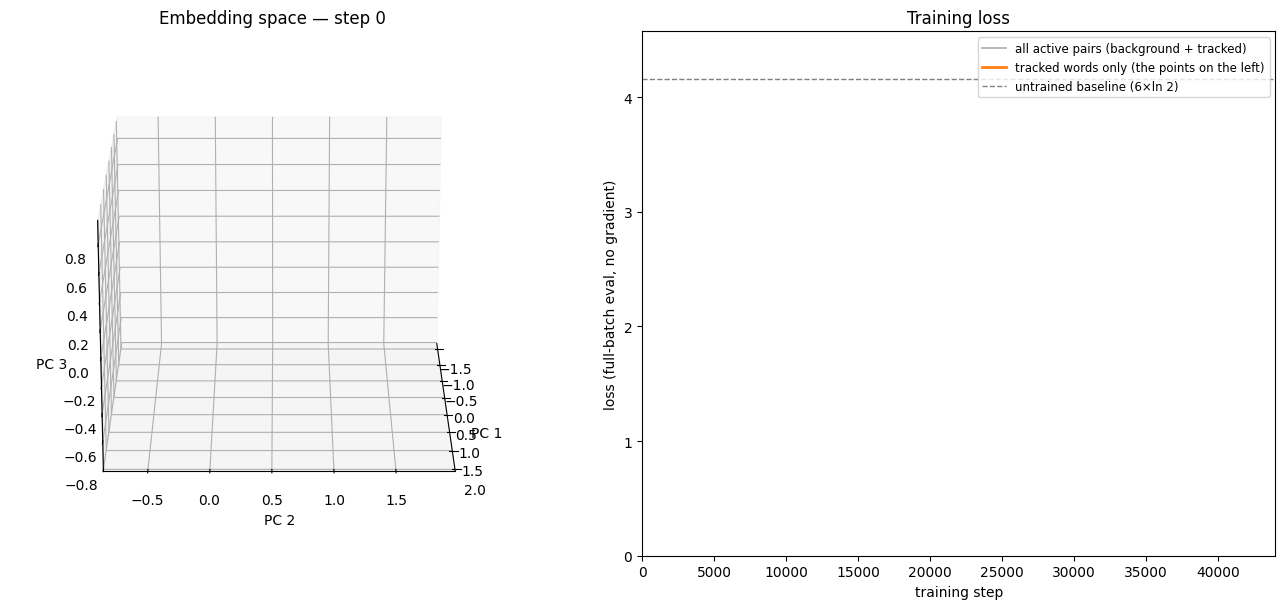

In [9]:

import ipywidgets as widgets
from IPython.display import display

_slider_fig = plt.figure(figsize=FIGSIZE)
_slider_output = widgets.Output()

def _on_slider_change(change):
    with _slider_output:
        _slider_output.clear_output(wait=True)
        render_frame(change["new"], fig=_slider_fig)
        display(_slider_fig)

slider = widgets.IntSlider(min=0, max=len(history) - 1, step=1, value=0,
                            description="snapshot", continuous_update=True,
                            layout=widgets.Layout(width="700px"))
slider.observe(_on_slider_change, names="value")

display(slider, _slider_output)
_on_slider_change({"new": 0})  # draw the first frame immediately



## Option B: export as MP4

Renders every snapshot to a PNG, then stitches them into a video with
`ffmpeg` (must be installed and on your `PATH`).


In [10]:

os.makedirs(FRAMES_DIR, exist_ok=True)
_export_fig = plt.figure(figsize=FIGSIZE)

for i in range(len(history)):
    render_frame(i, fig=_export_fig)
    _export_fig.savefig(f"{FRAMES_DIR}/frame_{i:04d}.png", dpi=DPI)
    if i % 40 == 0:
        print(f"rendered frame {i}/{len(history)}")

plt.close(_export_fig)
print(f"Wrote {len(history)} frames to '{FRAMES_DIR}/'.")


rendered frame 0/233


rendered frame 40/233


rendered frame 80/233


rendered frame 120/233


rendered frame 160/233


rendered frame 200/233


Wrote 233 frames to 'frames_curriculum/'.


In [11]:

cmd = [
    "ffmpeg", "-y", "-framerate", str(FRAMERATE),
    "-i", f"{FRAMES_DIR}/frame_%04d.png",
    "-pix_fmt", "yuv420p",
    "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2",
    OUTPUT_MP4,
]
result = subprocess.run(cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(result.stderr[-2000:])
    raise RuntimeError("ffmpeg failed \u2014 is it installed and on PATH?")
print(f"Saved {OUTPUT_MP4}")


Saved curriculum_embedding_and_loss.mp4


In [12]:

from IPython.display import Video
Video(OUTPUT_MP4, embed=True, width=900)
